# 05 — Classical Machine Learning

Train and evaluate the four classical model families on the feature table from notebook 04. Follow the pipeline decisions documented in `modelling_pipeline_decisions.md`.

**Inputs:**
- `data/processed/features_common_no_baro.csv` (main feature table)
- `reports/features/feature_inventory.csv` (family classification)

**Outputs:**
- `reports/results/results_table.csv` (the headline comparison table)
- `reports/results/per_fold_results.csv` (raw per-fold metrics for noise analysis)
- `reports/results/per_class_f1.csv` (per-class breakdown for all pipelines)
- `reports/figures/cm_loso_winning.png` (confusion matrix for the best LOSO pipeline)
- `reports/figures/cm_loso_ensemble.png` (confusion matrix for the ensemble)
- `reports/results/feature_importance.csv` (RF importance ranking for the winning configuration)
- `reports/results/best_pipeline.pkl` (the saved best pipeline for use in notebook 09)

**What this notebook does:**
1. Loads features and partitions them into feature sets A, B, C using the family classification from notebook 04.
2. Defines three cross-validation splitters for the E0, E1, and E2 evaluation levels.
3. Runs nested cross-validation for every pipeline at every evaluation level. The inner loop selects hyperparameters using session-grouped CV inside the training data. The outer loop produces the held-out scores.
4. Builds the comparison table with two drop columns: random to session and session to LOSO.
5. Runs a soft-voting ensemble of the best Random Forest and best XGBoost on the winning feature set.
6. Produces confusion matrices and a feature importance ranking for the winning pipeline.

Macro-F1 is the primary metric. Mean LOSO macro-F1 across folds is the selection criterion. Per-fold standard deviation is the tie-breaker.

## 1. Imports and configuration

In [ ]:
import json
import pickle
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    StratifiedKFold, GroupKFold, StratifiedGroupKFold, 
    LeaveOneGroupOut, GridSearchCV
)
from sklearn.metrics import (
    f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings('ignore')

try:
    from xgboost import XGBClassifier
    XGB_AVAILABLE = True
except ImportError:
    print('WARNING: XGBoost not installed. Run: pip install xgboost')
    XGB_AVAILABLE = False

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Paths (notebook lives in notebooks/) ---
PROJECT_ROOT = Path('..').resolve()
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORTS_DIR = PROJECT_ROOT / 'reports'
RESULTS_DIR = REPORTS_DIR / 'results'
FIGURES_DIR = REPORTS_DIR / 'figures'
FEATURES_DIR = REPORTS_DIR / 'features'

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MODES = ['stationary', 'walking', 'cycling', 'metro', 'bus', 'tram']
MODE_TO_ID = {m: i for i, m in enumerate(MODES)}

print('Paths and constants set.')

Paths and constants set.


## 2. Load features and define sets A, B, C

The three feature sets are an ablation chain: A is the basic time-domain set, B adds frequency-domain features, C adds cross-axis correlations, distribution shape, jerk statistics, signal magnitude area, peak count, zero-crossing rate, and axis std ratios. Each set strictly contains the previous one.

In [2]:
features_df = pd.read_csv(PROCESSED_DIR / 'features_common_no_baro.csv')
inventory = pd.read_csv(FEATURES_DIR / 'feature_inventory.csv')

meta_cols = ['session_id', 'participant', 'mode', 'mode_id', 'day',
             'window_index', 'window_start_s', 'window_end_s', 'flagged_frac']

# Feature set definitions by family
family_to_set = {
    'time_domain_basic':       ['A', 'B', 'C'],
    'slope':                   ['A', 'B', 'C'],
    'frequency_domain':        ['B', 'C'],
    'shape_and_energy':        ['C'],
    'cross_axis_correlation':  ['C'],
    'axis_std_ratio':          ['C'],
    'signal_magnitude_area':   ['C'],
    'peak_count':              ['C'],
    'zero_crossing_rate':      ['C'],
}

feature_sets = {'A': [], 'B': [], 'C': []}
for _, row in inventory.iterrows():
    feat = row['feature']
    fam = row['family']
    if fam not in family_to_set:
        continue
    for s in family_to_set[fam]:
        feature_sets[s].append(feat)

# Verify ablation chain: A subset of B subset of C
assert set(feature_sets['A']).issubset(set(feature_sets['B']))
assert set(feature_sets['B']).issubset(set(feature_sets['C']))

for s in ('A', 'B', 'C'):
    print(f'Set {s}: {len(feature_sets[s])} features')

print()
print(f'Dataset: {len(features_df)} windows across {features_df["participant"].nunique()} participants')
print(f'Modes: {sorted(features_df["mode"].unique())}')

Set A: 80 features
Set B: 100 features
Set C: 129 features

Dataset: 9721 windows across 3 participants
Modes: ['bus', 'cycling', 'metro', 'stationary', 'tram', 'walking']


## 3. Pre-extract arrays for fast cross-validation

Cross-validation will run many fits. Extracting the numpy arrays once avoids repeated dataframe operations and keeps the loops clean.

In [3]:
y = features_df['mode_id'].values
groups_session = features_df['session_id'].values
groups_participant = features_df['participant'].values

X_by_set = {s: features_df[feature_sets[s]].values for s in ('A', 'B', 'C')}

print('Class distribution:')
for cls_id, mode in enumerate(MODES):
    n = int(np.sum(y == cls_id))
    print(f'  {mode:12s}: {n:5d} windows ({100*n/len(y):.1f} %)')
print()
print(f'Sessions: {len(np.unique(groups_session))}')
print(f'Participants: {sorted(np.unique(groups_participant))}')

Class distribution:
  stationary  :  1680 windows (17.3 %)
  walking     :  1448 windows (14.9 %)
  cycling     :  1725 windows (17.7 %)
  metro       :  1722 windows (17.7 %)
  bus         :  1534 windows (15.8 %)
  tram        :  1612 windows (16.6 %)

Sessions: 36
Participants: ['athina', 'babis', 'xiomara']


## 4. Cross-validation splitters for E0, E1, E2

Three evaluation levels in increasing difficulty:

- **E0 (random window split):** 5-fold stratified. Windows from the same session may end up in different folds. Optimistic because of 50 percent window overlap.
- **E1 (session split):** 5-fold grouped by `session_id`. All windows from one recording stay in the same fold. Tests whether the model generalizes to new recordings from known users.
- **E2 (leave-one-subject-out):** 3 folds, one per participant. Tests cross-user generalization.

The inner CV used for hyperparameter selection is always session-grouped 3-fold over the training data. This protects the LOSO held-out user from any leakage during tuning.

In [ ]:
def get_outer_splitter(level: str):
    if level == 'E0':
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E1':
        return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E2':
        return LeaveOneGroupOut()
    raise ValueError(level)


def get_outer_groups(level: str):
    if level == 'E0':
        return None  # stratified, no grouping
    if level == 'E1':
        return groups_session
    if level == 'E2':
        return groups_participant
    raise ValueError(level)


def get_inner_splitter():
    # Always group by session for tuning, regardless of outer level.
    # Three folds keeps the inner search fast.
    return GroupKFold(n_splits=3)


# Confirm fold counts
for level in ('E0', 'E1', 'E2'):
    outer = get_outer_splitter(level)
    g = get_outer_groups(level)
    n = sum(1 for _ in outer.split(X_by_set['A'], y, g))
    print(f'{level}: {n} outer folds')

E0: 5 outer folds
E1: 5 outer folds
E2: 3 outer folds


## 5. Model factories and hyperparameter grids

Grids are deliberately small. With three LOSO folds, fold-to-fold variance is the relevant noise floor; large grids produce false precision rather than better models.

- **Majority baseline:** no hyperparameters.
- **Logistic regression:** L2 penalty, C in {0.1, 1.0, 10.0}. Pipeline includes a `StandardScaler` so the scaler is fit only on training folds. Trained on Feature Set A only.
- **Random Forest:** 300 trees, max_depth in {10, 20, None}, min_samples_leaf in {1, 5}. Trained on A, B, C.
- **XGBoost:** 300 trees, max_depth in {3, 5, 7}, learning_rate in {0.05, 0.1}. Trained on A, B, C.

Tree models receive raw features. Logistic regression receives standardized features.

In [5]:
def build_baseline():
    return DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE), {}


def build_lr():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(
            penalty='l2', solver='lbfgs', max_iter=2000,
            random_state=RANDOM_STATE,
        )),
    ])
    grid = {'clf__C': [0.1, 1.0, 10.0]}
    return pipe, grid


def build_rf():
    clf = RandomForestClassifier(
        n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE,
    )
    grid = {
        'max_depth':        [10, 20, None],
        'min_samples_leaf': [1, 5],
    }
    return clf, grid


def build_xgb():
    clf = XGBClassifier(
        n_estimators=300,
        objective='multi:softprob',
        num_class=len(MODES),
        tree_method='hist',
        n_jobs=-1,
        random_state=RANDOM_STATE,
        eval_metric='mlogloss',
        verbosity=0,
    )
    grid = {
        'max_depth':     [3, 5, 7],
        'learning_rate': [0.05, 0.1],
    }
    return clf, grid


# Define the full pipeline list
pipelines = []
pipelines.append(('Baseline', 'A', build_baseline))
pipelines.append(('LogReg', 'A', build_lr))
for fs in ('A', 'B', 'C'):
    pipelines.append(('RF', fs, build_rf))
if XGB_AVAILABLE:
    for fs in ('A', 'B', 'C'):
        pipelines.append(('XGBoost', fs, build_xgb))

print(f'Total pipelines: {len(pipelines)}')
for name, fs, _ in pipelines:
    print(f'  {name} + Set {fs}')

Total pipelines: 8
  Baseline + Set A
  LogReg + Set A
  RF + Set A
  RF + Set B
  RF + Set C
  XGBoost + Set A
  XGBoost + Set B
  XGBoost + Set C


## 6. Nested cross-validation function

For each outer fold: tune hyperparameters using `GridSearchCV` on the training data with session-grouped inner CV, refit on the full training fold with the best parameters, evaluate once on the held-out test fold. Return per-fold metrics, predictions, and the best hyperparameter dict.

The baseline skips inner CV because it has no hyperparameters. Logistic regression and Random Forest can accept groups through `GridSearchCV.fit`. XGBoost does too because we pass it through `GridSearchCV` the same way.

In [6]:
def run_nested_cv(model_factory, X, y, groups_outer, outer_splitter, inner_splitter,
                  has_hyperparams: bool):
    """Run nested CV. Returns a list of per-fold result dicts."""
    results = []

    for fold_idx, (train_idx, test_idx) in enumerate(
        outer_splitter.split(X, y, groups=groups_outer)
    ):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]
        # Inner CV always groups by session within the training data
        inner_groups = groups_session[train_idx]

        if has_hyperparams:
            estimator, grid = model_factory()
            gs = GridSearchCV(
                estimator=estimator,
                param_grid=grid,
                cv=inner_splitter,
                scoring='f1_macro',
                n_jobs=1,  # outer is already parallel inside the estimator
                refit=True,
            )
            gs.fit(X_tr, y_tr, groups=inner_groups)
            best = gs.best_estimator_
            best_params = gs.best_params_
        else:
            best, _ = model_factory()
            best.fit(X_tr, y_tr)
            best_params = {}

        y_pred = best.predict(X_te)
        macro_f1 = f1_score(y_te, y_pred, average='macro')

        # Held-out group identifier for reporting (e.g. which participant for E2)
        held_out = '_'.join(sorted(set(map(str, groups_outer[test_idx])))) if groups_outer is not None else f'fold_{fold_idx}'

        results.append({
            'fold':        fold_idx,
            'held_out':    held_out,
            'macro_f1':    float(macro_f1),
            'best_params': best_params,
            'y_true':      y_te,
            'y_pred':      y_pred,
            'fitted_model': best,  # kept for ensemble construction
        })

    return results

## 7. Run the full grid

For each pipeline at each evaluation level, run nested CV. Print a progress line per cell. Save intermediate results so a re-run does not redo work.

Approximate cost: roughly 30 to 60 minutes on a modern laptop. The slowest part is XGBoost on Feature Set C across the 5-fold E0 and E1 outer loops.

In [7]:
all_results = {}  # (model_name, feature_set, level) -> list of per-fold dicts

EVAL_LEVELS = ('E0', 'E1', 'E2')

for model_name, fs, factory in pipelines:
    X = X_by_set[fs]
    has_hp = (model_name != 'Baseline')
    for level in EVAL_LEVELS:
        key = (model_name, fs, level)
        if key in all_results:
            continue
        t0 = time.time()
        outer = get_outer_splitter(level)
        outer_groups = get_outer_groups(level)
        inner = get_inner_splitter()

        fold_results = run_nested_cv(
            model_factory=factory,
            X=X, y=y,
            groups_outer=outer_groups,
            outer_splitter=outer,
            inner_splitter=inner,
            has_hyperparams=has_hp,
        )
        all_results[key] = fold_results
        elapsed = time.time() - t0
        macro_mean = np.mean([r['macro_f1'] for r in fold_results])
        macro_std = np.std([r['macro_f1'] for r in fold_results])
        print(f'{model_name:9s} + {fs} | {level} | macro-F1 = {macro_mean:.3f} +/- {macro_std:.3f} | {elapsed:.0f}s')

Baseline  + A | E0 | macro-F1 = 0.050 +/- 0.000 | 0s
Baseline  + A | E1 | macro-F1 = 0.000 +/- 0.000 | 0s
Baseline  + A | E2 | macro-F1 = 0.046 +/- 0.002 | 0s
LogReg    + A | E0 | macro-F1 = 0.743 +/- 0.016 | 14s
LogReg    + A | E1 | macro-F1 = 0.415 +/- 0.084 | 13s
LogReg    + A | E2 | macro-F1 = 0.523 +/- 0.091 | 7s
RF        + A | E0 | macro-F1 = 0.902 +/- 0.006 | 81s
RF        + A | E1 | macro-F1 = 0.420 +/- 0.065 | 87s
RF        + A | E2 | macro-F1 = 0.624 +/- 0.061 | 49s
RF        + B | E0 | macro-F1 = 0.906 +/- 0.011 | 122s
RF        + B | E1 | macro-F1 = 0.431 +/- 0.068 | 143s
RF        + B | E2 | macro-F1 = 0.623 +/- 0.061 | 75s
RF        + C | E0 | macro-F1 = 0.911 +/- 0.015 | 181s
RF        + C | E1 | macro-F1 = 0.405 +/- 0.073 | 236s
RF        + C | E2 | macro-F1 = 0.569 +/- 0.080 | 113s
XGBoost   + A | E0 | macro-F1 = 0.928 +/- 0.011 | 743s
XGBoost   + A | E1 | macro-F1 = 0.381 +/- 0.056 | 731s
XGBoost   + A | E2 | macro-F1 = 0.563 +/- 0.073 | 354s
XGBoost   + B | E0 | mac

## 8. Per-fold results

Write every fold-level macro-F1 to disk. This is what we use to argue that differences smaller than fold-to-fold standard deviation are not meaningful.

In [19]:
per_fold_rows = []
for (model_name, fs, level), folds in all_results.items():
    for r in folds:
        per_fold_rows.append({
            'model':      model_name,
            'feature_set': fs,
            'level':      level,
            'fold':       r['fold'],
            'held_out':   r['held_out'],
            'macro_f1':   r['macro_f1'],
            'best_params': json.dumps(r['best_params']),
        })
per_fold = pd.DataFrame(per_fold_rows)
per_fold.to_csv(RESULTS_DIR / 'per_fold_results.csv', index=False)
print(f'Saved {len(per_fold)} per-fold rows to {RESULTS_DIR / "per_fold_results.csv"}')
per_fold.head(10)

Saved 104 per-fold rows to C:\Projects\this project-transport-mode\reports\results\per_fold_results.csv


,model,feature_set,level,fold,held_out,macro_f1,best_params
0,Baseline,A,E0,0,fold_0,0.050218,{}
1,Baseline,A,E0,1,fold_1,0.050240,{}
2,Baseline,A,E0,2,fold_2,0.050240,{}
3,Baseline,A,E0,3,fold_3,0.050240,{}
4,Baseline,A,E0,4,fold_4,0.050240,{}
5,Baseline,A,E2,0,athina,0.044961,{}
6,Baseline,A,E2,1,babis,0.049100,{}
7,Baseline,A,E2,2,xiomara,0.045328,{}
8,LogReg,A,E0,0,fold_0,0.749845,"{""clf__C"": 1.0}"
9,LogReg,A,E0,1,fold_1,0.748223,"{""clf__C"": 1.0}"


## 9. Headline comparison table

Aggregate per-fold results into the table from the pipeline document: one row per pipeline, columns for each evaluation level, and two drop columns. Drop columns are signed so a positive value means performance fell.

In [20]:
rows = []
for (model_name, fs, level), folds in all_results.items():
    f1s = np.array([r['macro_f1'] for r in folds])
    rows.append({
        'model':       model_name,
        'feature_set': fs,
        'level':       level,
        'macro_f1_mean': float(f1s.mean()),
        'macro_f1_std':  float(f1s.std()),
    })
agg = pd.DataFrame(rows)

# Pivot so each row is one pipeline and each evaluation level is a column
table = agg.pivot_table(
    index=['model', 'feature_set'],
    columns='level',
    values=['macro_f1_mean', 'macro_f1_std'],
)

# Flatten the multi-index columns
table.columns = [f'{a}_{b}' for a, b in table.columns]
table = table.reset_index()

# Add drop columns
table['drop_E0_to_E1'] = table['macro_f1_mean_E0'] - table['macro_f1_mean_E1']
table['drop_E1_to_E2'] = table['macro_f1_mean_E1'] - table['macro_f1_mean_E2']

# Sort by LOSO mean (primary selection criterion)
table = table.sort_values('macro_f1_mean_E2', ascending=False).reset_index(drop=True)

table.to_csv(RESULTS_DIR / 'results_table.csv', index=False)

display_cols = ['model', 'feature_set',
                'macro_f1_mean_E0', 'macro_f1_mean_E1', 'macro_f1_mean_E2',
                'macro_f1_std_E2',
                'drop_E0_to_E1', 'drop_E1_to_E2']
print('Headline results (sorted by LOSO mean macro-F1):')
print(table[display_cols].round(3).to_string(index=False))

Headline results (sorted by LOSO mean macro-F1):
   model feature_set  macro_f1_mean_E0  macro_f1_mean_E1  macro_f1_mean_E2  macro_f1_std_E2  drop_E0_to_E1  drop_E1_to_E2
      RF           A             0.902             0.596             0.624            0.061          0.305         -0.027
      RF           B             0.906             0.597             0.623            0.061          0.309         -0.026
      RF           C             0.911             0.587             0.569            0.080          0.324          0.018
 XGBoost           A             0.928             0.567             0.563            0.073          0.362          0.003
 XGBoost           B             0.924             0.568             0.559            0.069          0.356          0.009
 XGBoost           C             0.956             0.536             0.523            0.077          0.420          0.013
  LogReg           A             0.743             0.558             0.523            0.091      

## 10. Pick the winner

Selection criterion stated upfront in the pipeline document: mean LOSO macro-F1 across the three folds. Standard deviation across folds is the tie-breaker.

Pipelines whose mean LOSO macro-F1 falls within one fold-standard-deviation of the top are considered ties.

In [21]:
non_baseline = table[table['model'] != 'Baseline'].copy()
best_idx = non_baseline['macro_f1_mean_E2'].idxmax()
winner = non_baseline.loc[best_idx]
winner_model = winner['model']
winner_fs = winner['feature_set']
winner_mean = winner['macro_f1_mean_E2']
winner_std = winner['macro_f1_std_E2']

print(f'Winning pipeline: {winner_model} + Set {winner_fs}')
print(f'  LOSO macro-F1: {winner_mean:.3f} +/- {winner_std:.3f}')
print()

ties = non_baseline[
    non_baseline['macro_f1_mean_E2'] >= (winner_mean - winner_std)
]
print(f'Pipelines within one std of the winner ({len(ties)}):')
print(ties[['model', 'feature_set', 'macro_f1_mean_E2', 'macro_f1_std_E2']]
      .round(3).to_string(index=False))

Winning pipeline: RF + Set A
  LOSO macro-F1: 0.624 +/- 0.061

Pipelines within one std of the winner (4):
  model feature_set  macro_f1_mean_E2  macro_f1_std_E2
     RF           A             0.624            0.061
     RF           B             0.623            0.061
     RF           C             0.569            0.080
XGBoost           A             0.563            0.073


## 11. Soft-voting ensemble of RF and XGBoost

Average the predicted class probabilities of the best Random Forest fold-model and the best XGBoost fold-model on the same outer fold. This is cheap because both base models are already fitted. If the ensemble outperforms both base models it suggests their errors are complementary.

In [11]:
# A cleaner approach: re-run the outer split and compute ensemble in one pass
def run_ensemble_cv(feature_set: str, level: str):
    X = X_by_set[feature_set]
    outer = get_outer_splitter(level)
    outer_groups = get_outer_groups(level)
    inner = get_inner_splitter()

    rf_factory = build_rf
    xgb_factory = build_xgb

    ensemble_results = []
    for fold_idx, (train_idx, test_idx) in enumerate(outer.split(X, y, groups=outer_groups)):
        X_tr, X_te = X[train_idx], X[test_idx]
        y_tr, y_te = y[train_idx], y[test_idx]
        inner_groups = groups_session[train_idx]

        # Fit RF with grid search
        rf_est, rf_grid = rf_factory()
        rf_gs = GridSearchCV(rf_est, rf_grid, cv=inner, scoring='f1_macro',
                              n_jobs=1, refit=True)
        rf_gs.fit(X_tr, y_tr, groups=inner_groups)
        rf_proba = rf_gs.best_estimator_.predict_proba(X_te)

        # Fit XGB with grid search
        xgb_est, xgb_grid = xgb_factory()
        xgb_gs = GridSearchCV(xgb_est, xgb_grid, cv=inner, scoring='f1_macro',
                               n_jobs=1, refit=True)
        xgb_gs.fit(X_tr, y_tr, groups=inner_groups)
        xgb_proba = xgb_gs.best_estimator_.predict_proba(X_te)

        avg_proba = (rf_proba + xgb_proba) / 2
        y_pred = np.argmax(avg_proba, axis=1)
        macro_f1 = f1_score(y_te, y_pred, average='macro')

        held_out = '_'.join(sorted(set(map(str, outer_groups[test_idx])))) if outer_groups is not None else f'fold_{fold_idx}'
        ensemble_results.append({
            'fold': fold_idx, 'held_out': held_out,
            'macro_f1': float(macro_f1),
            'y_true': y_te, 'y_pred': y_pred,
            'rf_best_params': rf_gs.best_params_,
            'xgb_best_params': xgb_gs.best_params_,
        })
    return ensemble_results


# Run ensemble on the winning feature set across all three eval levels
ensemble_all = {}
if XGB_AVAILABLE:
    for level in EVAL_LEVELS:
        t0 = time.time()
        ensemble_all[level] = run_ensemble_cv(winner_fs, level)
        f1s = [r['macro_f1'] for r in ensemble_all[level]]
        elapsed = time.time() - t0
        print(f'Ensemble (RF + XGB) on Set {winner_fs} | {level} | '
              f'macro-F1 = {np.mean(f1s):.3f} +/- {np.std(f1s):.3f} | {elapsed:.0f}s')

Ensemble (RF + XGB) on Set A | E0 | macro-F1 = 0.929 +/- 0.008 | 721s
Ensemble (RF + XGB) on Set A | E1 | macro-F1 = 0.387 +/- 0.057 | 686s
Ensemble (RF + XGB) on Set A | E2 | macro-F1 = 0.578 +/- 0.064 | 373s


## 12. Add ensemble to the results table

In [22]:
if XGB_AVAILABLE and ensemble_all:
    ensemble_row = {
        'model': 'Ensemble (RF+XGB)',
        'feature_set': winner_fs,
    }
    for level in EVAL_LEVELS:
        f1s = np.array([r['macro_f1'] for r in ensemble_all[level]])
        ensemble_row[f'macro_f1_mean_{level}'] = float(f1s.mean())
        ensemble_row[f'macro_f1_std_{level}']  = float(f1s.std())
    ensemble_row['drop_E0_to_E1'] = ensemble_row['macro_f1_mean_E0'] - ensemble_row['macro_f1_mean_E1']
    ensemble_row['drop_E1_to_E2'] = ensemble_row['macro_f1_mean_E1'] - ensemble_row['macro_f1_mean_E2']

    table_with_ensemble = pd.concat([table, pd.DataFrame([ensemble_row])], ignore_index=True)
    table_with_ensemble = table_with_ensemble.sort_values('macro_f1_mean_E2', ascending=False).reset_index(drop=True)
    table_with_ensemble.to_csv(RESULTS_DIR / 'results_table.csv', index=False)

    print('Final table including ensemble:')
    print(table_with_ensemble[display_cols].round(3).to_string(index=False))
else:
    print('Ensemble skipped (XGBoost unavailable).')
    table_with_ensemble = table

Final table including ensemble:
            model feature_set  macro_f1_mean_E0  macro_f1_mean_E1  macro_f1_mean_E2  macro_f1_std_E2  drop_E0_to_E1  drop_E1_to_E2
               RF           A             0.902             0.596             0.624            0.061          0.305         -0.027
               RF           B             0.906             0.597             0.623            0.061          0.309         -0.026
Ensemble (RF+XGB)           A             0.929             0.578             0.578            0.064          0.351          0.000
               RF           C             0.911             0.587             0.569            0.080          0.324          0.018
          XGBoost           A             0.928             0.567             0.563            0.073          0.362          0.003
          XGBoost           B             0.924             0.568             0.559            0.069          0.356          0.009
          XGBoost           C             0.956    

In [18]:
# ============================================================================
# PATCH: Use StratifiedGroupKFold for E1
#
# Reason: the original GroupKFold produced session-split folds with missing
# mode classes (visible in the baseline E1 = 0.000 row). StratifiedGroupKFold
# keeps the session grouping but enforces balanced mode distribution per fold,
# which fixes the artificially deflated E1 numbers in the headline table.
#
# This cell:
#   1. Redefines get_outer_splitter so E1 uses StratifiedGroupKFold.
#   2. Clears only the E1 entries from all_results (E0 and E2 stay cached).
#   3. Re-runs every pipeline on E1 with the new splitter.
#   4. Re-runs the ensemble on E1 only.
# ============================================================================

from sklearn.model_selection import StratifiedGroupKFold


def get_outer_splitter(level: str):
    """Patched: E1 now uses StratifiedGroupKFold for mode-balanced session splits."""
    if level == 'E0':
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E1':
        return StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    if level == 'E2':
        return LeaveOneGroupOut()
    raise ValueError(level)


# --- Invalidate E1 cache ---
e1_keys = [k for k in list(all_results.keys()) if k[2] == 'E1']
for k in e1_keys:
    del all_results[k]
print(f'Cleared {len(e1_keys)} E1 entries from all_results')

if 'ensemble_all' in dir() and ensemble_all and 'E1' in ensemble_all:
    del ensemble_all['E1']
    print('Cleared E1 from ensemble_all')


# --- Re-run E1 for every pipeline ---
inner = get_inner_splitter()
for model_name, fs, factory in pipelines:
    X = X_by_set[fs]
    has_hp = (model_name != 'Baseline')
    key = (model_name, fs, 'E1')
    if key in all_results:
        continue
    t0 = time.time()
    outer = get_outer_splitter('E1')
    outer_groups = get_outer_groups('E1')

    fold_results = run_nested_cv(
        model_factory=factory,
        X=X, y=y,
        groups_outer=outer_groups,
        outer_splitter=outer,
        inner_splitter=inner,
        has_hyperparams=has_hp,
    )
    all_results[key] = fold_results
    elapsed = time.time() - t0
    macro_mean = np.mean([r['macro_f1'] for r in fold_results])
    macro_std = np.std([r['macro_f1'] for r in fold_results])
    print(f'{model_name:9s} + {fs} | E1 (StratifiedGroupKFold) | '
          f'macro-F1 = {macro_mean:.3f} +/- {macro_std:.3f} | {elapsed:.0f}s')


# --- Re-run ensemble on E1 only ---
if XGB_AVAILABLE and 'ensemble_all' in dir() and ensemble_all is not None:
    t0 = time.time()
    ensemble_all['E1'] = run_ensemble_cv(winner_fs, 'E1')
    f1s = [r['macro_f1'] for r in ensemble_all['E1']]
    elapsed = time.time() - t0
    print(f'Ensemble (RF + XGB) on Set {winner_fs} | E1 (StratifiedGroupKFold) | '
          f'macro-F1 = {np.mean(f1s):.3f} +/- {np.std(f1s):.3f} | {elapsed:.0f}s')

Cleared 8 E1 entries from all_results
Cleared E1 from ensemble_all
Baseline  + A | E1 (StratifiedGroupKFold) | macro-F1 = 0.044 +/- 0.005 | 0s
LogReg    + A | E1 (StratifiedGroupKFold) | macro-F1 = 0.558 +/- 0.075 | 41s
RF        + A | E1 (StratifiedGroupKFold) | macro-F1 = 0.596 +/- 0.112 | 145s
RF        + B | E1 (StratifiedGroupKFold) | macro-F1 = 0.597 +/- 0.112 | 200s
RF        + C | E1 (StratifiedGroupKFold) | macro-F1 = 0.587 +/- 0.120 | 204s
XGBoost   + A | E1 (StratifiedGroupKFold) | macro-F1 = 0.567 +/- 0.089 | 767s
XGBoost   + B | E1 (StratifiedGroupKFold) | macro-F1 = 0.568 +/- 0.086 | 774s
XGBoost   + C | E1 (StratifiedGroupKFold) | macro-F1 = 0.536 +/- 0.102 | 935s
Ensemble (RF + XGB) on Set A | E1 (StratifiedGroupKFold) | macro-F1 = 0.578 +/- 0.096 | 919s


## 13. Confusion matrices on LOSO

Confusion matrices are a primary deliverable, not a supplementary one. The story of this project lives in the bus, metro, tram confusion. Concatenate the held-out predictions across all three LOSO folds to get a single matrix representing the cross-user case.

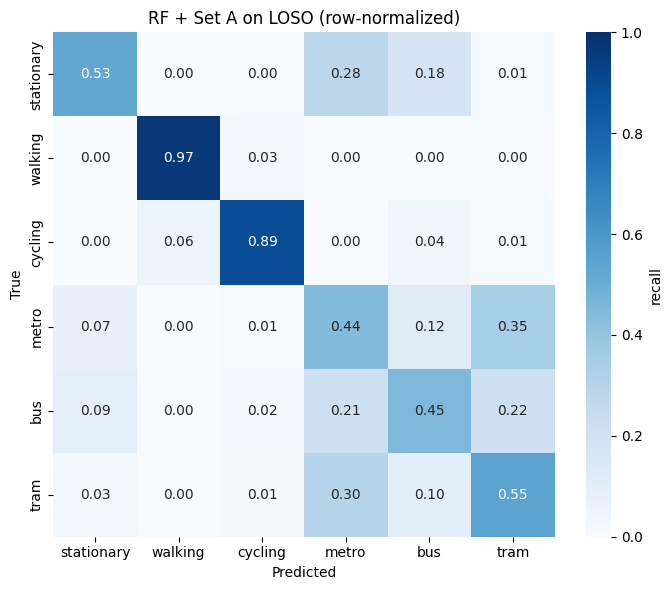

Saved: cm_loso_winning.png


In [13]:
def aggregate_cm(folds):
    """Concatenate predictions across folds and compute a single normalized CM."""
    y_true_all = np.concatenate([r['y_true'] for r in folds])
    y_pred_all = np.concatenate([r['y_pred'] for r in folds])
    cm = confusion_matrix(y_true_all, y_pred_all, labels=list(range(len(MODES))))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    return cm, cm_norm, y_true_all, y_pred_all


def plot_cm(cm_norm, title, savepath):
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(
        cm_norm, annot=True, fmt='.2f', cmap='Blues',
        xticklabels=MODES, yticklabels=MODES, ax=ax, cbar_kws={'label': 'recall'},
        vmin=0, vmax=1,
    )
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(savepath, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()


# Winning single-model CM on LOSO
winner_folds = all_results[(winner_model, winner_fs, 'E2')]
cm_w, cm_w_norm, _, _ = aggregate_cm(winner_folds)
plot_cm(
    cm_w_norm,
    f'{winner_model} + Set {winner_fs} on LOSO (row-normalized)',
    FIGURES_DIR / 'cm_loso_winning.png'
)
print(f'Saved: cm_loso_winning.png')

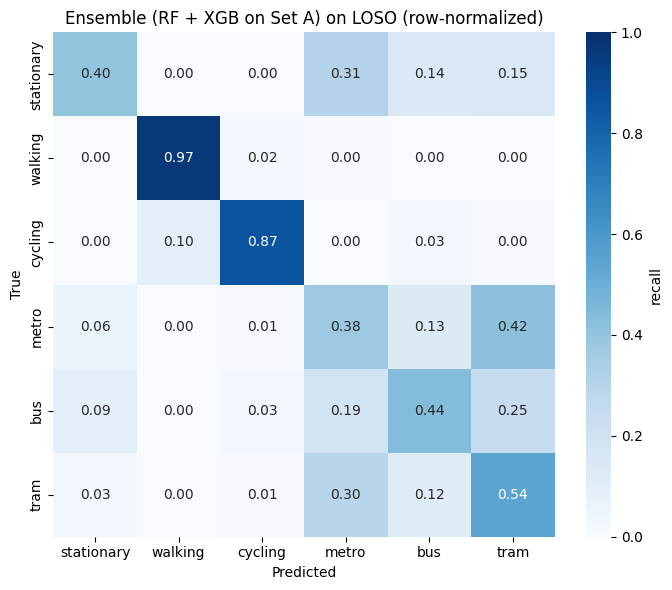

Saved: cm_loso_ensemble.png


In [14]:
# Ensemble CM on LOSO
if XGB_AVAILABLE and ensemble_all:
    cm_e, cm_e_norm, _, _ = aggregate_cm(ensemble_all['E2'])
    plot_cm(
        cm_e_norm,
        f'Ensemble (RF + XGB on Set {winner_fs}) on LOSO (row-normalized)',
        FIGURES_DIR / 'cm_loso_ensemble.png'
    )
    print(f'Saved: cm_loso_ensemble.png')

## 14. Per-class F1 across pipelines

Macro-F1 hides which classes drive the overall score. Per-class F1 lets us see where each pipeline succeeds and fails, especially across the bus, metro, tram cluster.

In [15]:
rows = []
for (model_name, fs, level), folds in all_results.items():
    if level != 'E2':
        continue
    y_true_all = np.concatenate([r['y_true'] for r in folds])
    y_pred_all = np.concatenate([r['y_pred'] for r in folds])
    f1_per_class = f1_score(y_true_all, y_pred_all,
                              labels=list(range(len(MODES))), average=None)
    row = {'model': model_name, 'feature_set': fs}
    for cls_id, mode in enumerate(MODES):
        row[f'f1_{mode}'] = float(f1_per_class[cls_id])
    rows.append(row)

# Add the ensemble
if XGB_AVAILABLE and ensemble_all:
    y_true_all = np.concatenate([r['y_true'] for r in ensemble_all['E2']])
    y_pred_all = np.concatenate([r['y_pred'] for r in ensemble_all['E2']])
    f1_per_class = f1_score(y_true_all, y_pred_all,
                              labels=list(range(len(MODES))), average=None)
    row = {'model': 'Ensemble (RF+XGB)', 'feature_set': winner_fs}
    for cls_id, mode in enumerate(MODES):
        row[f'f1_{mode}'] = float(f1_per_class[cls_id])
    rows.append(row)

per_class = pd.DataFrame(rows).sort_values('f1_metro', ascending=False).reset_index(drop=True)
per_class.to_csv(RESULTS_DIR / 'per_class_f1.csv', index=False)

print('Per-class F1 on LOSO (sorted by metro F1):')
print(per_class.round(3).to_string(index=False))

Per-class F1 on LOSO (sorted by metro F1):
            model feature_set  f1_stationary  f1_walking  f1_cycling  f1_metro  f1_bus  f1_tram
               RF           A          0.618       0.945       0.912     0.404   0.469    0.509
               RF           B          0.617       0.946       0.922     0.371   0.497    0.517
Ensemble (RF+XGB)           A          0.513       0.926       0.896     0.357   0.460    0.453
               RF           C          0.523       0.958       0.888     0.356   0.419    0.451
          XGBoost           A          0.480       0.918       0.892     0.350   0.447    0.432
          XGBoost           B          0.480       0.906       0.888     0.341   0.503    0.435
           LogReg           A          0.769       0.691       0.727     0.319   0.406    0.336
          XGBoost           C          0.384       0.966       0.892     0.293   0.374    0.352
         Baseline           A          0.000       0.000       0.202     0.261   0.000    0.0

## 15. Feature importance for the winning configuration

If the winner is a Random Forest, the importance ranking comes directly from `feature_importances_` averaged across the LOSO folds. If the winner is XGBoost, the same applies. The ranking tells us which feature families carry the discriminative information across users.

In [16]:
if winner_model in ('RF', 'XGBoost'):
    folds = all_results[(winner_model, winner_fs, 'E2')]
    importances = np.stack([
        f['fitted_model'].feature_importances_ for f in folds
    ])
    mean_imp = importances.mean(axis=0)
    std_imp = importances.std(axis=0)

    imp_df = pd.DataFrame({
        'feature': feature_sets[winner_fs],
        'importance_mean': mean_imp,
        'importance_std':  std_imp,
    }).sort_values('importance_mean', ascending=False).reset_index(drop=True)

    imp_df = imp_df.merge(inventory, on='feature', how='left')
    imp_df.to_csv(RESULTS_DIR / 'feature_importance.csv', index=False)

    print('Top 25 features by mean importance across LOSO folds:')
    print(imp_df.head(25)[['feature', 'family', 'importance_mean', 'importance_std']]
          .round(4).to_string(index=False))

    print()
    print('Importance summed by family:')
    fam_imp = (imp_df.groupby('family')['importance_mean'].sum()
                .sort_values(ascending=False))
    print(fam_imp.round(3).to_string())
else:
    print(f'Winner ({winner_model}) has no native feature importance.')

Top 25 features by mean importance across LOSO folds:
          feature            family  importance_mean  importance_std
       lin_ay_iqr time_domain_basic           0.0409          0.0097
           gz_iqr time_domain_basic           0.0381          0.0080
       lin_ay_rms time_domain_basic           0.0364          0.0056
       lin_ay_std time_domain_basic           0.0354          0.0049
linacc_mag_median time_domain_basic           0.0344          0.0095
           gz_std time_domain_basic           0.0336          0.0044
       lin_az_iqr time_domain_basic           0.0292          0.0025
           gy_iqr time_domain_basic           0.0269          0.0074
       lin_az_std time_domain_basic           0.0268          0.0088
         gz_range time_domain_basic           0.0259          0.0012
   linacc_mag_rms time_domain_basic           0.0243          0.0074
  linacc_mag_mean time_domain_basic           0.0237          0.0054
       lin_az_rms time_domain_basic           0.0

## 16. Save the best pipeline for external evaluation

Refit the winning pipeline on all available data with the most common best-hyperparameters across the LOSO folds. This is the model that notebook 09 will use to evaluate on external participants.

In [17]:
def majority_params(folds):
    """Pick the most common parameter setting across folds. Ties go to the first."""
    from collections import Counter
    keys = sorted(folds[0]['best_params'].keys())
    serialised = [tuple(f['best_params'][k] for k in keys) for f in folds]
    most_common, _ = Counter(serialised).most_common(1)[0]
    return dict(zip(keys, most_common))


winner_folds = all_results[(winner_model, winner_fs, 'E2')]
best_params = majority_params(winner_folds)
print(f'Most common best params on LOSO: {best_params}')

if winner_model == 'RF':
    final, _ = build_rf()
    final.set_params(**best_params)
elif winner_model == 'XGBoost':
    final, _ = build_xgb()
    final.set_params(**best_params)
elif winner_model == 'LogReg':
    final, _ = build_lr()
    final.set_params(**best_params)

X_final = X_by_set[winner_fs]
final.fit(X_final, y)

artefact = {
    'model':         final,
    'feature_set':   winner_fs,
    'feature_names': feature_sets[winner_fs],
    'mode_to_id':    MODE_TO_ID,
    'best_params':   best_params,
    'winner_model':  winner_model,
}
with open(RESULTS_DIR / 'best_pipeline.pkl', 'wb') as f:
    pickle.dump(artefact, f)
print(f'Saved best pipeline to {RESULTS_DIR / "best_pipeline.pkl"}')

Most common best params on LOSO: {'max_depth': 20, 'min_samples_leaf': 1}
Saved best pipeline to C:\Projects\this project-transport-mode\reports\results\best_pipeline.pkl


## 17. Summary

Reading order for the report:
1. `reports/results/results_table.csv` for the headline table.
2. `reports/results/per_fold_results.csv` for the noise floor discussion.
3. `reports/figures/cm_loso_winning.png` and `reports/figures/cm_loso_ensemble.png` for the qualitative confusion analysis.
4. `reports/results/per_class_f1.csv` for the per-mode breakdown.
5. `reports/results/feature_importance.csv` for the feature family discussion.

Open questions to address in the report discussion:
1. How much of the drop from E0 to E1 is window-overlap leakage versus genuine session generalization difficulty.
2. Which features lose relative importance from E0 to E2: orientation-dependent per-axis features should fall, orientation-invariant magnitudes and ratios should rise.
3. Whether the ensemble buys anything beyond the best single model.
4. Which mode confusions persist on LOSO and what physical reason explains them.